# Phase 28 — Comprehensive System Ablation Matrix

**Method**: `RA-MedFiLM-BARR` — multi-domain ultrasound segmentation, phase-gated.
**Classification**: `PHASE28_CANONICAL_COMPREHENSIVE_SYSTEM_ABLATION_MATRIX`.
**Population**: `ROUTER_DEVELOPMENT` (n = 4957). Fixed budget 25 % (K = 1239).
**Arms**: 13 — A0–A8, R1–R3, F1.

This notebook is a **reviewer-facing, read-only, fully executed** rendering of the
frozen Phase-28 artifacts.

It performs **no training**, **no model forward**, **no OOF recomputation**,
**no membership recomputation**, **no metric recomputation** and **no bootstrap
recomputation**. It reads frozen JSON / CSV / PNG artifacts, renders them in full,
and asserts frozen SHAs and counts. `ROUTER_HOLDOUT` (n=875), `VAL808` (n=808) and
`TEST` (n=1683) are never opened.

This notebook is the **compliance-repaired** edition that supersedes the
unexecuted notebook with SHA `72cfbc12e76a58fab3449e6dbf8163cbe988e7473e716e10bf87741fa8c10326`.
The superseded edition is archived byte-for-byte at
`reports/audits/phase28_comprehensive_ablation_pre_notebook_compliance_repair.ipynb`.

## 0. Deterministic environment and repository discovery

The repository root is discovered deterministically by walking `Path.cwd()` and its
parents until a known frozen Phase-28 artifact is found — no machine-specific path
is baked into the notebook.

In [1]:
import base64, csv, hashlib, io, json, re, sys
from pathlib import Path

import pandas as pd
from IPython.display import Image, display, Markdown

pd.set_option("display.max_rows", None)
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 240)
pd.set_option("display.max_colwidth", None)


def discover_root() -> Path:
    # Walk cwd and parents until a frozen Phase-28 artifact is found.
    marker = Path("reports") / "audits" / "phase28_final_freeze.json"
    for base in [Path.cwd(), *Path.cwd().parents]:
        if (base / marker).exists():
            return base
    raise FileNotFoundError(f"could not locate Phase-28 repository root from {Path.cwd()}")


ROOT = discover_root()
AUD = ROOT / "reports" / "audits"
TAB = ROOT / "reports" / "tables"
FIG = ROOT / "reports" / "figures"
D28 = ROOT / "data_cache" / "phase28_router_variants_v1_2"
F1C = ROOT / "data_cache" / "phase28_f1_refiner_v1_2"
RCK = {"R1": ROOT / "checkpoints" / "phase28_router_R1_no_deep",
       "R2": ROOT / "checkpoints" / "phase28_router_R2_no_task",
       "R3": ROOT / "checkpoints" / "phase28_router_R3_scalar_only"}
F1_CK = ROOT / "checkpoints" / "phase28_refiner_F1_no_pglobal"
F1_EXP = ROOT / "experiments" / "phase28_refiner_F1_no_pglobal"


def sha256_file(p: Path) -> str:
    h = hashlib.sha256()
    with open(p, "rb") as f:
        for chunk in iter(lambda: f.read(1 << 20), b""):
            h.update(chunk)
    return h.hexdigest()


def J(name: str):
    return json.load(open(AUD / name, encoding="utf-8"))


def T(name: str) -> pd.DataFrame:
    return pd.read_csv(TAB / name, dtype=str)


def show_table(df, caption):
    """Render a COMPLETE pandas table: no truncation of rows or columns."""
    print(caption)
    print(f'[complete rendering: {len(df)} rows x {df.shape[1]} cols]')
    display(df.style.hide(axis='index') if hasattr(df.style, 'hide') else df)

print("repository root:", ROOT)
print("pandas", pd.__version__)

repository root: D:\Softfors\jup
pandas 3.0.5


## 1. Purpose and governing ruling

Phase 28 executes the **canonical comprehensive system ablation** under the
supervisor's operationalization ruling v1.2. The ruling froze R1/R2/R3/F1 as
`SEPARATELY_TRAINED_CONTROLLED_ABLATION_VARIANT` and superseded `NO_TRAINING` with
`ABLATION_ONLY_TRAINING_AUTHORIZED_FOR_R1_R2_R3_F1`.

This notebook is the **post-execution compliance repair**. Science is unchanged:
no training, no forward, no metric recomputation.

In [2]:
rul = J("phase28_supervisor_operationalization_ruling_v1_2.json")
repair = J("phase28_notebook_compliance_repair_classification.json")
print("ruling classification :", rul.get("classification"))
print("repair classification :", repair["classification"])
print("scope                 :", repair["scope_statement"][:120], "...")
for k, v in repair["frozen_invariants"].items():
    print(f"  {k:42s} = {v}")

ruling classification : SUPERVISOR_PROSPECTIVE_OPERATIONALIZATION_RULING
repair classification : PHASE28_REVIEWER_NOTEBOOK_COMPLIANCE_REPAIR_ONLY
scope                 : Repair the canonical Phase28 reviewer notebook ONLY. Scientific execution, checkpoints, OOF predictions, memberships, me ...
  science_changed                            = False
  training_changed                           = False
  checkpoints_changed                        = False
  OOF_predictions_changed                    = False
  memberships_changed                        = False
  metrics_changed                            = False
  statistics_changed                         = False
  figures_scientific_content_changed         = False
  canonical_bundle_changed                   = False


## 2. Entry gate

The compliance-repair entry gate re-verifies the frozen terminal, the unchanged
base final freeze, the exact pre-repair notebook SHA, and the locked populations.

In [3]:
g = J("phase28_notebook_compliance_repair_entry_gate.json")
for k in ("required_terminal", "observed_terminal", "terminal_match",
          "gate_pass", "all_pass"):
    print(f"{k:20s} = {g.get(k)}")
print()
print("canonical notebook (pre-repair):")
print("  sha256      :", g["canonical_notebook"]["sha256"])
print("  required    :", g["canonical_notebook"]["required_sha256"])
print("  sha_exact   :", g["canonical_notebook"]["sha_exact"])
print()
print("governance state:", json.dumps(g["governance_state"], indent=2))
assert g["terminal_match"] is True
assert g["canonical_notebook"]["sha_exact"] is True
assert g["gate_pass"] is True

required_terminal    = PHASE28_COMPREHENSIVE_ABLATION_MATRIX_COMPLETE__CORE_ROUTER_AND_REFINER_ABLATIONS_FROZEN__PHASE29_ELIGIBLE_NOT_STARTED
observed_terminal    = PHASE28_COMPREHENSIVE_ABLATION_MATRIX_COMPLETE__CORE_ROUTER_AND_REFINER_ABLATIONS_FROZEN__PHASE29_ELIGIBLE_NOT_STARTED
terminal_match       = True
gate_pass            = True
all_pass             = True

canonical notebook (pre-repair):
  sha256      : 72cfbc12e76a58fab3449e6dbf8163cbe988e7473e716e10bf87741fa8c10326
  required    : 72cfbc12e76a58fab3449e6dbf8163cbe988e7473e716e10bf87741fa8c10326
  sha_exact   : True

governance state: {
  "phase29_started": false,
  "phase30_started": false,
  "ROUTER_HOLDOUT_reads": 0,
  "VAL808_reads": 0,
  "TEST_reads": 0
}


## 3. Specification binding (v1.2, zero drift)

Seventeen authoritative v1.2 artifacts are SHA-256 bound. Historical v1.0 / v1.1
artifacts are preserved and unmodified.

In [4]:
b = J("phase28_execution_spec_v1_2_binding.json")
print("artifacts bound :", b.get("artifact_count", len(b.get("artifacts", []))))
print("zero_drift      :", b.get("zero_drift"))
print("all_pass        :", b.get("all_pass"))
assert b.get("zero_drift") is True

artifacts bound : 17
zero_drift      : True
all_pass        : True


## 4. Scope and prohibitions

No `ROUTER_HOLDOUT` read (n=875, Phase 30), no `TEST` read (n=1683, Phase 39),
no canonical-bundle mutation, no policy retuning, no deployment-model replacement.

In [5]:
m = J("phase28_comprehensive_ablation_matrix.json")
for k in ("ROUTER_HOLDOUT_reads", "TEST_reads", "VAL808_reads",
          "canonical_bundle_changed", "policy_retuning_performed",
          "deployment_model_replaced"):
    print(f"{k:30s} = {m.get(k)}")
assert m["ROUTER_HOLDOUT_reads"] == 0 and m["TEST_reads"] == 0 and m["VAL808_reads"] == 0
assert m["canonical_bundle_changed"] is False

ROUTER_HOLDOUT_reads           = 0
TEST_reads                     = 0
VAL808_reads                   = 0
canonical_bundle_changed       = False
policy_retuning_performed      = False
deployment_model_replaced      = False


## 5. Population ownership

The evaluated population is `ROUTER_DEVELOPMENT` (n=4957). Every sample belongs to
exactly one governed population; none is drawn from a locked cohort.

In [6]:
p = J("phase28_population_ownership_audit.json")
print(json.dumps(p, indent=1)[:1200])
print()
print("matrix population:", m["population"], "| n =", m["n"], "| K =", m["K"])

{
 "artifact": "phase28_population_ownership_audit",
 "phase": 28,
 "classification": "PHASE28_ABLATION_POPULATION_OWNERSHIP_AUDIT",
 "governance_only": true,
 "execution": "NONE",
 "blocker_class": "HARD_BLOCKER",
 "question": "Which population is Phase28 authorized to evaluate ablations on?",
 "determination": "Phase28_ABLATION_POPULATION = ROUTER_DEVELOPMENT (DEV)",
 "determination_basis": [
  {
   "source": "reports/audits/phase26_downstream_phase_boundary_audit.json",
   "sha256": "9703974040e67487deabf067e2492872b9c5e8b9c64de349a1e8497663d1c4fe",
   "statement": "phase28.population = 'ROUTER_DEVELOPMENT (DEV)'"
  },
  {
   "source": "reports/tables/phase24_data_role_contract.csv",
   "sha256": "d8ff7674b7a5c8e056628dd0e1921982cfa0825d77a9d5b0f0d5e4e1335890d7",
   "statement": "ROUTER_DEVELOPMENT role = cross-fitted gain labels + router fitting + threshold calibration; may_select_lambda_or_threshold=yes"
  },
  {
   "source": "reports/audits/phase27_phase_boundaries_contract_v1_1.

## 6. Training-input provenance gate

All upstream inputs are SHA-bound: Phase25B features (202-D), Phase25C label table
(4957 rows), Phase25D CV5 manifest + role manifests, Phase25A ROI-030 cache, and
the frozen Phase25F reuse contract + fold checkpoints.

In [7]:
pv = J("phase28_training_input_provenance_gate.json")
print("all_pass:", pv.get("all_pass"))
print("top-level keys:", list(pv.keys()))
assert pv.get("all_pass") is True

all_pass: True
top-level keys: ['artifact', 'phase', 'classification', 'recovery_method', 'phase25b_input_features', 'phase25b_scalar_feature_names', 'phase25c_target_table', 'phase25d_cv_and_role_manifests', 'phase25d_protocol_contracts', 'phase25d_oof_inference_implementation', 'phase25a_roi030_and_protocol', 'phase25c_oof_inference_implementation', 'phase25f_post_safety_reuse', 'population', 'all_material_inputs_present', 'blocked_terminal', 'all_pass', 'missing_inputs']


## 7. OOF inference semantics binding

The exact inference semantics were physically recovered from the predecessor
implementations before any Phase-28 forward:

* **Router (Phase 25D)**: `torch.no_grad()`, FP32, batch 128.
* **Refiner (Phase 25C)**: `m.eval()` + `torch.inference_mode()`, **FP32, no
  autocast**, `np.ascontiguousarray(..., float32)`, batch 8, model loaded
  `map_location="cpu"`.
* **`S_omega` (Phase 25F)**: `model.eval()` + `inference_mode()`, raw logit.

The OOF path deliberately does **not** reuse the training AMP settings.

In [8]:
sem = J("phase28_oof_inference_semantics_binding.json")
print(json.dumps(sem, indent=1)[:1400])

{
 "artifact": "phase28_oof_inference_semantics_binding",
 "phase": 28,
 "classification": "PRE_EXECUTION_OOF_INFERENCE_SEMANTICS_RECOVERY_BINDING",
 "recovery_method": "physical_source_inspection__not_memory",
 "purpose": "Recover the EXACT OOF inference semantics of the canonical Phase25D router and Phase25A/25C refiner so that Phase28 R1/R2/R3/F1 OOF replay is scientifically identical where it must be, and differs ONLY in the frozen ablated factor.",
 "router_oof_inference_semantics": {
  "source_script": {
   "path": "scripts/analysis/train_phase25d_router.py",
   "sha256": "fc7c1bdf263ae4551dcb8f170d3203adb8540fbc189846265b74f6eca1541e91"
  },
  "device": "torch.device('cuda' if torch.cuda.is_available() else 'cpu')  # trainer L209",
  "model_mode": "model.eval()  # L357",
  "gradient_mode": "torch.no_grad()  # L359",
  "autocast": "NOT USED for router OOF prediction (no torch.autocast in the OOF block)",
  "input_dtype": "torch.from_numpy(ot_x_norm) -> float32 (features .astype(n

## 8. Thirteen-arm registry

The complete 13-arm matrix at fixed 25 % budget (K = 1239).

In [9]:
mat = J("phase28_comprehensive_ablation_matrix.json")
arms13 = pd.DataFrame(mat["arms"])
print("arms:", mat["arm_count"], "| A-arms:", mat["A_arms"], "| variants:", mat["variant_arms"])
show_table(arms13[["arm", "role", "definition"]],
           "Table — arm registry (complete)")

arms: 13 | A-arms: ['A0', 'A1', 'A2', 'A3', 'A4', 'A5', 'A6', 'A7', 'A8'] | variants: ['R1', 'R2', 'R3', 'F1']
Table — arm registry (complete)
[complete rendering: 13 rows x 3 cols]


arm,role,definition
A0,ENDPOINT_REFERENCE,global-only (routing absent; no refinement)
A1,ENDPOINT_REFERENCE,"always-refine (routing absent, full budget)"
A2,ROUTING_SIGNAL_COMPARATOR,"random routing (seeded, budget-matched null)"
A3,ROUTING_SIGNAL_COMPARATOR,entropy routing (GT-free uncertainty proxy)
A4,ROUTING_SIGNAL_COMPARATOR,margin routing (GT-free margin proxy)
A5,ROUTING_SIGNAL_COMPARATOR,predicted-ROI-size routing (GT-free geometry proxy)
A6,ADJACENT_INCREMENTAL_CONTRAST,learned paired-gain routing (H1 test)
A7,ADJACENT_INCREMENTAL_CONTRAST,A6 + resource cost U = delta_hat - lambda*C
A8,MANDATORY_COMPONENT_ISOLATION,A7 + post-safety S_omega (CANONICAL BASELINE)
R1,PRIMARY_REFERENCE_NOT_PRE_REGISTERED,"router without deep global features (10 scalars + Embedding(4,16), width 26)"


## 9. Core contrast topology — A0–A8 preserved

The v1.1 contrast map is preserved unchanged. A0/A1 are endpoint references;
A2–A5 are GT-free routing-signal comparators; A6/A7 are adjacent incremental
contrasts; A8 is the mandatory component isolation (canonical baseline).

In [10]:
cm = pd.read_csv(TAB / "phase28_core_contrast_map.csv", dtype=str)
show_table(cm, "Table — core contrast map (complete)")

Table — core contrast map (complete)
[complete rendering: 13 rows x 8 cols]


ablation_id,arm_definition,primary_reference_arm,contrast_type,single_factor_isolated,scientific_question,authoritative_source,source_sha
A0,"global-only (global reference, no refinement, no routing)",A8,ENDPOINT_REFERENCE,ROUTING_ABSENT_FULL(sys),what is the compute floor and preservation reference? (delta vs global),reports/tables/phase24_ablation_plan.csv,422967fa3484b19d90bfc3b2146278aa69c6bd7a34e42ae3dbcb43a9ccca9087
A1,always-refine (refine every action-available sample),A8,ENDPOINT_REFERENCE,ROUTING_ABSENT_FULL(sys),what is the compute/accuracy ceiling with no routing?,reports/tables/phase24_ablation_plan.csv,422967fa3484b19d90bfc3b2146278aa69c6bd7a34e42ae3dbcb43a9ccca9087
A2,"random routing (seeded, budget-matched null)",A6,ROUTING_SIGNAL_COMPARATOR,ROUTING_SIGNAL,does a learned router beat a seeded random router at equal budget?,reports/tables/phase24_ablation_plan.csv,422967fa3484b19d90bfc3b2146278aa69c6bd7a34e42ae3dbcb43a9ccca9087
A3,entropy routing (GT-free uncertainty proxy),A6,ROUTING_SIGNAL_COMPARATOR,ROUTING_SIGNAL,does the learned router beat a simple entropy proxy at equal budget?,reports/tables/phase24_ablation_plan.csv,422967fa3484b19d90bfc3b2146278aa69c6bd7a34e42ae3dbcb43a9ccca9087
A4,margin routing (GT-free margin proxy),A6,ROUTING_SIGNAL_COMPARATOR,ROUTING_SIGNAL,does the learned router beat a simple margin proxy at equal budget?,reports/tables/phase24_ablation_plan.csv,422967fa3484b19d90bfc3b2146278aa69c6bd7a34e42ae3dbcb43a9ccca9087
A5,predicted-ROI-size routing (GT-free geometry proxy),A6,ROUTING_SIGNAL_COMPARATOR,ROUTING_SIGNAL,does the learned router beat a pure ROI-size heuristic at equal budget?,reports/tables/phase24_ablation_plan.csv,422967fa3484b19d90bfc3b2146278aa69c6bd7a34e42ae3dbcb43a9ccca9087
A6,learned paired-gain routing (H1 test),A0,ADJACENT_INCREMENTAL_CONTRAST,ROUTING_SIGNAL_INFORMED,does a learned pre-execution predictor of paired gain add value over global-only?,reports/tables/phase24_ablation_plan.csv,422967fa3484b19d90bfc3b2146278aa69c6bd7a34e42ae3dbcb43a9ccca9087
A7,A6 + resource cost (U = delta_hat - lambda*C),A6,ADJACENT_INCREMENTAL_CONTRAST,UTILITY_RESOURCE_TERM,does adding an explicit resource-cost term change the accuracy-compute frontier? (H5),reports/audits/phase25g_a7_a8_controlled_comparison_contract.json,ef3c25da49a530e99cc33adaced031be4988432370181c7e8a994803ede1c503
A8,A7 + post-safety S_omega (CANONICAL BASELINE),A7,MANDATORY_COMPONENT_ISOLATION,POST_SAFETY_S_OMEGA,does S_omega reduce harmful replacement? (H3). Physically frozen matched isolation (single difference).,reports/audits/phase25g_a7_a8_identity_control_audit.json,49246e3b32b669b04e5b339b177e82783089266d5ab8cf825d89c89443a5e1c3
R1,router without deep global features,A8,PRIMARY_REFERENCE_NOT_PRE_REGISTERED,ROUTER_FEATURE_DEPTH,does deep global-feature depth matter for routing? (OPERATIONALIZATION BLOCKED),reports/tables/phase24_ablation_plan.csv,422967fa3484b19d90bfc3b2146278aa69c6bd7a34e42ae3dbcb43a9ccca9087


## 10. Architecture parameter assertions

Four new architectures were implemented and asserted:
R1 = 12,225 · R2 = 34,689 · R3 = 10,113 · F1 = 1,276,257 parameters.

In [11]:
reg = J("phase28_training_run_registry.json")
variant_params = (pd.DataFrame(reg["runs"])
                  .groupby("variant", as_index=False)["param_count"].first()
                  .sort_values("variant"))
show_table(variant_params, "Table — variant parameter counts (from frozen registry)")
expected_params = {"R1": 12225, "R2": 34689, "R3": 10113, "F1": 1276257}
for _, r in variant_params.iterrows():
    assert int(r["param_count"]) == expected_params[r["variant"]], r["variant"]
print("all four parameter counts match the frozen contract")

Table — variant parameter counts (from frozen registry)
[complete rendering: 4 rows x 2 cols]


variant,param_count
F1,1276257
R1,12225
R2,34689
R3,10113


all four parameter counts match the frozen contract


## 11. R1 — no deep global features

R1 removes the 96-D deep global block. Input = 10 scalars + `Embedding(4,16)` →
projected width 26. Topology preserved downstream of the widened stem.

In [12]:
prot = J("phase28_router_variant_training_protocol_binding_v1_2.json")
print(json.dumps(prot, indent=1)[:1100])

{
 "phase": 28,
 "method": "RA-MedFiLM-BARR",
 "governance_only": true,
 "execution": "NONE",
 "generated_utc": "2026-10-02T12:35:00Z",
 "artifact": "phase28_router_variant_training_protocol_binding_v1_2",
 "classification": "ROUTER_ABLATION_TRAINING_PROTOCOL_INHERITANCE_BINDING",
 "applies_to": [
  "R1",
  "R2",
  "R3"
 ],
 "inherits": "Phase25D router-training protocol",
 "protocol_revision": "ra_medfilm_barr_router_training_v1_2_1",
 "physically_recovered": true,
 "recovery_method": "physical_artifact_inspection__not_memory",
 "authoritative_sources": {
  "phase25d_frozen_training_spec_binding_v1_2_1": {
   "path": "reports/audits/phase25d_frozen_training_spec_binding_v1_2_1.json",
   "sha256": "f590b7170dad0a149d5b9c69a00dd88e76504466318599d2bbd8b3daf86ca6c6"
  },
  "phase25d_cv_protocol_v1_2_1": {
   "path": "reports/audits/phase25d_cv_protocol_v1_2_1.json",
   "sha256": "276e45f42fa00d74a5338dbef15ed990f548d1a992223e2afb2623c7fe08471e"
  },
  "phase25d_nested_cv_split_contract_v1

## 12. R2 — no task_id conditioning

R2 removes the task embedding entirely: 202 numeric features, no embedding.

## 13. R3 — scalar-only feature-set control

R3 keeps only the 10 Phase25B scalars (width 10): a feature-set control that
isolates how much signal the scalar block alone carries.

## 14. Router OOF contract

Each variant produces exactly one OOF score per sample (4957) using the inherited
Phase25D protocol: `StratifiedGroupKFold(5, shuffle=True, random_state=42)`,
group = composite `group_key`, stratification = `domain`, sort
`[domain, group_key, sample_id]`.

In [13]:
oc = J("phase28_router_variant_oof_contract_v1_2.json")
print(json.dumps(oc, indent=1)[:900])
print()
for v in ("R1", "R2", "R3"):
    df = pd.read_csv(D28 / f"phase28_router_{v}_oof_scores.csv", dtype=str)
    print(f"{v} OOF rows = {len(df):5d}  | unique sample_id = {df['sample_id'].nunique():5d} "
          f"| columns = {list(df.columns)}")
    assert len(df) == 4957 and df["sample_id"].nunique() == 4957
print("all three OOF tables: exactly-once coverage of 4957 samples confirmed")

{
 "phase": 28,
 "method": "RA-MedFiLM-BARR",
 "governance_only": true,
 "execution": "NONE",
 "generated_utc": "2026-10-02T12:35:00Z",
 "artifact": "phase28_router_variant_oof_contract_v1_2",
 "classification": "ROUTER_ABLATION_OOF_AND_SEED_CONTRACT",
 "applies_to": [
  "R1",
  "R2",
  "R3"
 ],
 "oof_required": true,
 "per_fold_rule": {
  "train_on": "that fold's inherited FIT rows",
  "model_selection_on": "inherited EARLY_STOP rows",
  "predict_on": "inherited OUTER_TARGET rows"
 },
 "every_row_exactly_one_oof_score": true,
 "n_rows": 4957,
 "leakage_requirement": "no sample contributes to fitting or checkpoint selection for the model that predicts that sample",
 "final_all_dev_refit_required": false,
 "deployment_candidates": false,
 "seed_policy": "reuse exact Phase25D fold seed 42000 + outer_fold_index",
 "different_seeds_for_ablations": false,
 "seed_recovery_ambiguous": false,
 "

R1 OOF rows =  4957  | unique sample_id =  4957 | columns = ['sample_id', 'domain', 'task_id', 'ro

## 15. Router leakage guard

Targets are sliced as `y_all[fit_idx]` / `y_all[es_idx]` only. The OUTER_TARGET
target slice is never read during training. The OOF CSV contains no forbidden
outcome field.

In [14]:
lg = J("phase28_router_variant_leakage_guard.json")
print("all_pass:", lg.get("all_pass"))
for k in ("ot_targets_not_read", "forbidden_outcome_fields_absent", "fit_es_slices_only"):
    if k in lg:
        print(f"  {k:34s} = {lg[k]}")
assert lg.get("all_pass") is True

all_pass: True


## 16. Router normalization

Scalar indices `[192..197, 200, 201]` are standardized per fold with FIT-only
statistics (ddof=0); R1/R3 additionally normalize their local scalar block. Any
constant (`sigma < 1e-12`) maps to 0.0.

## 17. Router membership freeze — outcome barrier

K = floor(0.25 × 4957) = **1239**. Membership was frozen and SHA'd **before** any
outcome was opened. Rank Δ̂ DESC, tie-break `sample_id` ASC. `scalar_tau` is
NOT_APPLICABLE at fixed K.

In [15]:
br = J("phase28_router_membership_barrier.json")
print("K =", br.get("K"), "| population n =", br.get("n"))
for v in ("R1", "R2", "R3"):
    mem = pd.read_csv(D28 / f"phase28_router_{v}_membership_K1239.csv", dtype=str)
    print(f"  {v} membership rows = {len(mem)}")
    assert len(mem) == 1239
print("membership sizes confirmed = 1239 for R1/R2/R3")

K = 1239 | population n = None
  R1 membership rows = 1239
  R2 membership rows = 1239
  R3 membership rows = 1239
membership sizes confirmed = 1239 for R1/R2/R3


## 18. Router outcome opening

Outcomes were opened only after the membership barrier was recorded. The frozen
outcome is the Phase25C paired-gain label table (true ΔDice).

In [16]:
oo = J("phase28_outcome_opening.json")
print(json.dumps(oo, indent=1)[:1000])

{
 "artifact": "phase28_outcome_opening",
 "phase": 28,
 "classification": "POST_BARRIER_OUTCOME_OPENING",
 "barrier_artifact": "reports/audits/phase28_router_membership_barrier.json",
 "barrier_sha256": "3609fe39fa2ace13889c93d0407b8afa33b86da9f0f0a0713492f45584a40a2a",
 "opened_fields": [
  "delta_dice",
  "gain_category",
  "global_dice",
  "candidate_refined_dice"
 ],
 "outcome_source": "data_cache/phase25c_barr_oof_paired_gain_labels_v1_2/phase25c_oof_paired_gain_labels.csv",
 "outcome_source_sha256": "fd6ca32c33a3bddb75f986b1350d54ec35b11d3bf5cb0fdc029962a5aa94865f",
 "membership_frozen_before_opening": true,
 "all_pass": true
}


## 19. Router primary metrics

At fixed 25 % budget: precision@budget, benefit capture, mean true ΔDice among
routed, harmful activation share, beneficial coverage, missed benefit, oracle
regret. **No deployment winner is selected.**

In [17]:
rp = J("phase28_router_primary_metrics.json")
v = rp["variants"]
rows = []
for k in ("A6_C7_canonical", "R1", "R2", "R3"):
    d = v[k]
    rows.append({"arm": k, "n_routed": d["n_routed"],
                 "precision_at_budget": d["precision_at_budget"],
                 "benefit_capture": d["benefit_capture"],
                 "mean_true_delta_dice_routed": d["mean_true_delta_dice_routed"],
                 "harmful_activation_share": d["harmful_activation_share"],
                 "beneficial_coverage": d["beneficial_coverage"],
                 "missed_benefit": d["missed_benefit"],
                 "oracle_regret": d["oracle_regret"]})
show_table(pd.DataFrame(rows), "Table — router primary metrics (complete)")
print("no_deployment_winner_selected:", rp.get("no_deployment_winner_selected"))
assert rp["no_deployment_winner_selected"] is True

Table — router primary metrics (complete)
[complete rendering: 4 rows x 9 cols]


arm,n_routed,precision_at_budget,benefit_capture,mean_true_delta_dice_routed,harmful_activation_share,beneficial_coverage,missed_benefit,oracle_regret
A6_C7_canonical,1239,0.667474,0.602199,0.007247,0.332526,0.298018,0.397801,0.285698
R1,1239,0.583535,0.495314,0.003320,0.373688,0.260541,0.504686,0.392583
R2,1239,0.547215,0.245687,0.001191,0.435028,0.244324,0.754313,0.642210
R3,1239,0.566586,0.243912,0.001251,0.422922,0.252973,0.756088,0.643984


no_deployment_winner_selected: True


## 20. Router membership overlap

Overlap vs canonical A6/C7 membership quantifies how much the ablated routers
re-select the same samples.

In [18]:
df = T("phase28_table_04_router_membership_overlap.csv")
show_table(df, "Table — router membership overlap (complete)")

Table — router membership overlap (complete)
[complete rendering: 3 rows x 7 cols]


variant,K_variant,K_reference,n_overlap_with_A6C7,n_union,jaccard,overlap_fraction_of_variant
R1,1239,1239,636,1842,0.345276872964,0.513317191283
R2,1239,1239,313,2165,0.144572748268,0.252623083132
R3,1239,1239,300,2178,0.137741046832,0.242130750605


## 21. F1 — trained refiner without p_global input channel

Canonical refiner input = RGB **+** `p_global` → `(4,256,256)`. F1 input = RGB only
→ `(3,256,256)`. The `p_global` channel is **physically absent**; the stem
`Conv2d(4→16)` becomes `Conv2d(3→16)`. Everything else is frozen.

In [19]:
fc = J("phase28_f1_input_contract_v1_2.json")
print(json.dumps(fc, indent=1)[:1000])

{
 "phase": 28,
 "method": "RA-MedFiLM-BARR",
 "governance_only": true,
 "execution": "NONE",
 "generated_utc": "2026-10-02T12:40:00Z",
 "artifact": "phase28_f1_input_contract_v1_2",
 "classification": "F1_REFINER_INPUT_CHANNEL_FREEZE",
 "canonical_refiner_input": {
  "channels": 4,
  "layout": "[R,G,B,p_global_crop]",
  "shape": [
   null,
   4,
   256,
   256
  ]
 },
 "F1_input": {
  "channels": 3,
  "layout": "[R,G,B]",
  "shape": [
   null,
   3,
   256,
   256
  ]
 },
 "p_global_channel_physically_absent": true,
 "forbidden": [
  "feed zeros as fourth channel",
  "mask the fourth channel",
  "reuse the 4-channel weights"
 ],
 "requires_new_checkpoint_family": true,
 "new_checkpoint_root": "checkpoints/phase28_refiner_F1_no_pglobal/",
 "roi_geometry_remains_canonical": true,
 "roi_proposal_threshold": 0.3,
 "roi_expansion": 1.5,
 "crop_resolution": 256,
 "p_global_still_used_for_ROI_proposal": true,
 "controlled_factor": "REFINER_INPUT_P_GLOBAL_CHANNEL",
 "not_the_controlled_factor

## 22. F1 ROI geometry remains canonical

ROI-0.30 canonical geometry is retained: threshold 0.30, expansion 1.50, 256 crop,
512 canvas. F1 changes only the refiner input channels.

In [20]:
geo = J("phase28_f1_membership_rule_v1_2.json")
print(json.dumps(geo, indent=1)[:800])

{
 "phase": 28,
 "method": "RA-MedFiLM-BARR",
 "governance_only": true,
 "execution": "NONE",
 "generated_utc": "2026-10-02T12:40:00Z",
 "artifact": "phase28_f1_membership_rule_v1_2",
 "classification": "F1_INTEGRATED_ROUTING_MEMBERSHIP_FREEZE",
 "applies_to": [
  "F1"
 ],
 "routing_membership": "EXACT CANONICAL A8 25% OOF ROUTING MEMBERSHIP",
 "rerun_or_recalibrate_B_phi": false,
 "K_changed": false,
 "sample_selection_altered_by_F1_outcomes": false,
 "isolation_purpose": "isolate the refiner-input intervention",
 "integrated_reference": "A8/C9 canonical system with exact A8 membership retained"
}


## 23. F1 training protocol

3-fold cross-fit (seed 42, group-safe domain-stratified, FIT 0.9 / EARLY_STOP 0.1).
Loss `0.5*BCEWithLogits + 0.5*Dice(1e-6)`; AdamW(lr=1e-4, wd=1e-4);
`CosineAnnealingLR(T_max=100)`; batch 8; 100 epochs; patience 15; min EARLY_STOP
total loss; AMP on CUDA; `cudnn.deterministic`.

In [21]:
fp = J("phase28_f1_training_protocol_binding_v1_2.json")
print(json.dumps(fp, indent=1)[:1100])

{
 "phase": 28,
 "method": "RA-MedFiLM-BARR",
 "governance_only": true,
 "execution": "NONE",
 "generated_utc": "2026-10-02T12:40:00Z",
 "artifact": "phase28_f1_training_protocol_binding_v1_2",
 "classification": "F1_REFINER_ABLATION_TRAINING_PROTOCOL_INHERITANCE_BINDING",
 "applies_to": [
  "F1"
 ],
 "inherits": "Phase25A/Phase25C leakage-safe regional-refiner protocol",
 "physically_recovered": true,
 "recovery_method": "physical_artifact_inspection__not_memory",
 "authoritative_sources": {
  "phase25a_crossfit_protocol.json": {
   "path": "reports/audits/phase25a_crossfit_protocol.json",
   "exists": true,
   "sha256": "6868b5562fe02929e13d63905ca74a759e20dec3c01b14eef331e4cb948f55ce"
  },
  "phase25a_refiner_architecture_binding.json": {
   "path": "reports/audits/phase25a_refiner_architecture_binding.json",
   "exists": true,
   "sha256": "2f0d23878c855db60347e3d7225bd06703646e76263ae2ff82d485923474ad9b"
  },
  "phase25a_augmentation_binding.json": {
   "path": "reports/audits/pha

## 24. F1 OOF integrity

Leakage-safe: each sample's OOF crop is produced by the fold model that did not
train on that sample. 4957 crops are written; contiguity and finiteness verified.

In [22]:
total = 0
for k in range(3):
    idx = pd.read_csv(F1C / f"fold{k}_refined_crop_index.csv", dtype=str)
    print(f"  fold{k}: {len(idx):5d} OOF refined crops")
    total += len(idx)
print("F1 OOF refined crops total =", total)
assert total == 4957
pv2 = J("phase28_f1_pipeline_validation.json")
print()
print("pipeline validation all_pass:", pv2.get("all_pass"))
assert pv2.get("all_pass") is True

  fold0:  1657 OOF refined crops
  fold1:  1652 OOF refined crops
  fold2:  1648 OOF refined crops
F1 OOF refined crops total = 4957

pipeline validation all_pass: True


## 25. F1 primary refiner-level result (NEGATIVE — genuine)

On the A7 EXECUTE membership: canonical mean ΔD = **+0.0072466**, F1 mean
ΔD = **−0.0441799**. The paired difference (F1 − canonical) = **−0.0514266**,
CI95 [−0.0554756, −0.0475745]; F1 is worse than global in 968/1239 samples.

In [23]:
rl = J("phase28_f1_refiner_level_comparison.json")
print("n_paired                     :", rl["n_paired"])
print("canonical mean ΔD            :", f"{rl['canonical_candidate_mean_delta']:+.7f}")
print("F1 mean ΔD                   :", f"{rl['f1_candidate_mean_delta']:+.7f}")
print("paired diff (F1 − canonical) :", f"{rl['paired_mean_delta_difference_f1_minus_canonical']:+.7f}")
print("CI95                         :", [f"{x:+.7f}" for x in rl["paired_bootstrap_ci95"]])
print("n_canonical_better / n_f1_better:", rl["n_canonical_better"], "/", rl["n_f1_better"])
assert rl["paired_mean_delta_difference_f1_minus_canonical"] < 0

n_paired                     : 1239
canonical mean ΔD            : +0.0072466
F1 mean ΔD                   : -0.0441799
paired diff (F1 − canonical) : -0.0514266
CI95                         : ['-0.0554756', '-0.0475745']
n_canonical_better / n_f1_better: 1048 / 191


## 26. F1 integrated secondary (spec §24)

For integrated F1: recompute **only** the deterministic 20-D `S_omega` feature
vector from the F1 candidate, then run the **already-frozen** Phase25F OOF fold
model for the sample's `router_cv_fold`. No `S_omega` retraining; leakage-safe fold
ownership; fold checkpoints physically present (analysis AVAILABLE).

In [24]:
fi = J("phase28_f1_integrated_secondary.json")
print("n_A7_execute         :", fi["n_A7_execute"])
print("n_F1_accept          :", fi["n_f1_accept"], "| n_F1_fallback:", fi["n_f1_fallback"])
print("F1 integrated mean ΔD:", f"{fi['f1_integrated_mean_delta_dice']:+.7f}")
print("canonical A8 mean ΔD :", f"{fi['canonical_A8_mean_delta_dice']:+.7f}")
print("paired diff (F1 − A8):", f"{fi['paired_mean_difference_f1_minus_canonical']:+.7f}",
      "CI95", [f"{x:+.7f}" for x in fi["paired_bootstrap_ci95"]])
print("S_omega retrained    :", fi["s_omega_retrained"])
assert fi["s_omega_retrained"] is False

n_A7_execute         : 1239
n_F1_accept          : 1109 | n_F1_fallback: 130
F1 integrated mean ΔD: -0.0325853
canonical A8 mean ΔD : +0.0075158
paired diff (F1 − A8): -0.0398949 CI95 ['-0.0428957', '-0.0371943']
S_omega retrained    : False


## 27. A0–A5 artifact reconstruction evidence

Reconstructed from frozen canonical artifacts with **no new forward**. A0
global-mean Dice = 0.915783; A1 always-refine mean ΔD = 0.001658 (harm 0.4267).

In [25]:
a05 = J("phase28_a0_a5_artifact_reconstruction_verification.json")
rows = []
for k, rec in a05["rows"].items():
    rows.append({"arm": k, "definition": rec.get("definition"),
                 "requires_new_model_forward": rec.get("requires_new_model_forward"),
                 "sufficient": rec.get("sufficient"),
                 "score_space": rec.get("score_space")})
show_table(pd.DataFrame(rows), "Table — A0–A5 reconstruction rule (complete)")

Table — A0–A5 reconstruction rule (complete)
[complete rendering: 6 rows x 5 cols]


arm,definition,requires_new_model_forward,sufficient,score_space
A0,global-only,False,True,global Dice on ROUTER_DEVELOPMENT
A1,always-refine,False,True,refined Dice on ROUTER_DEVELOPMENT
A2,random routing,False,True,frozen Phase25E C3 membership
A3,entropy routing,False,True,frozen Phase25E C4 membership
A4,margin routing,False,True,frozen Phase25E C5 membership
A5,predicted-ROI-size routing,False,True,frozen Phase25E C6 membership


## 28. A6–A8 prior canonical evidence

A6/C7 learned route, A7/C8 resource gate (K = 1239 EXECUTE), A8/C9 post-safety
(1205 ACCEPT_REFINEMENT / 34 FALLBACK_GLOBAL).

In [26]:
a68 = J("phase28_a6_a8_prior_evidence_reconstruction.json")
rows = []
for name in ("A6_learned_router_C7", "A7_C8_plus_resource", "A8_C9_post_safety"):
    if name in a68:
        rec = a68[name]
        st = rec.get("stats", {})
        rows.append({"arm": name, "policy_id": rec.get("policy_id"),
                     "n": st.get("n"), "mean_true_delta": st.get("mean_true_delta"),
                     "n_beneficial": st.get("n_beneficial"),
                     "n_harmful": st.get("n_harmful"),
                     "status": rec.get("status")})
show_table(pd.DataFrame(rows), "Table — A6–A8 prior evidence (complete)")
print("canonical bundle sha256:", a68.get("canonical_bundle_sha256"))

Table — A6–A8 prior evidence (complete)
[complete rendering: 2 rows x 7 cols]


arm,policy_id,n,mean_true_delta,n_beneficial,n_harmful,status
A6_learned_router_C7,C7_budget0.25,1239,0.007247,827,412,SATISFIED_BY_PRIOR_CANONICAL_EVIDENCE
A7_C8_plus_resource,C8_lambda0.25_budget0.25,1239,0.007247,827,412,SATISFIED_BY_PRIOR_CANONICAL_EVIDENCE


canonical bundle sha256: f7aebb0f646bcc8de49fa91b70a4c4cc1051c9998ab6b055a8d4d187809cb3d9


## 29. Thirteen-arm ablation matrix

The complete 13-arm matrix at fixed 25 % budget. The F1 row carries the **true
integrated F1 outcome**, not a placeholder.

In [27]:
arm_df = T("phase28_ablation_matrix_13arm.csv")
show_table(arm_df, "Table — 13-arm ablation matrix (complete)")
assert len(arm_df) == 13

Table — 13-arm ablation matrix (complete)
[complete rendering: 13 rows x 13 cols]


arm,role,definition,primary_reference_arm,n_routed,sum_true_delta_dice,mean_true_delta_dice_routed,n_beneficial_routed,n_harmful_routed,harmful_activation_share,evidence_class,fixed_budget_K,budget
A0,ENDPOINT_REFERENCE,global-only (routing absent; no refinement),A8,0,0,0.0,0,0,0.0,nan,nan,nan
A1,ENDPOINT_REFERENCE,"always-refine (routing absent, full budget)",A8,4957,8.219101516,0.001658079789,2775,2115,0.426669356466,nan,nan,nan
A2,ROUTING_SIGNAL_COMPARATOR,"random routing (seeded, budget-matched null)",A6,1239,1.7512847168,0.001413466277,669,550,0.44390637611,nan,1239,0.25
A3,ROUTING_SIGNAL_COMPARATOR,entropy routing (GT-free uncertainty proxy),A6,1239,8.9028050945,0.007185476267,844,395,0.318805488297,nan,1239,0.25
A4,ROUTING_SIGNAL_COMPARATOR,margin routing (GT-free margin proxy),A6,1239,8.8209427109,0.007119404932,843,396,0.319612590799,nan,1239,0.25
A5,ROUTING_SIGNAL_COMPARATOR,predicted-ROI-size routing (GT-free geometry proxy),A6,1239,-0.5369508867,-0.000433374404,597,575,0.46408393866,nan,1239,0.25
A6,ADJACENT_INCREMENTAL_CONTRAST,learned paired-gain routing (H1 test),A0,1239,8.9785736244,0.007246629237,827,412,0.332526230831,PRIOR_CANONICAL_EVIDENCE_EXACT,1239,0.25
A7,ADJACENT_INCREMENTAL_CONTRAST,A6 + resource cost U = delta_hat - lambda*C,A6,1239,8.9785736244,0.007246629237,827,412,0.332526230831,PRIOR_CANONICAL_EVIDENCE_EXACT,1239,0.25
A8,MANDATORY_COMPONENT_ISOLATION,A7 + post-safety S_omega (CANONICAL BASELINE),A7,1205,9.0564839294,0.007515754298,815,390,0.323651452282,PRIOR_CANONICAL_EVIDENCE_EXACT,1239,0.25
R1,PRIMARY_REFERENCE_NOT_PRE_REGISTERED,"router without deep global features (10 scalars + Embedding(4,16), width 26)",A6,1239,4.1140619729,0.003320469712,723,463,0.373688458434,PHASE28_TRAINED_ABLATION_VARIANT,1239,0.25


## 30. Per-domain results

Per-domain ΔDice for the canonical route, reconstructed from the frozen Phase25C
paired-gain label table (read-only, no recomputation).

In [28]:
labs = pd.read_csv(
    ROOT / "data_cache" / "phase25c_barr_oof_paired_gain_labels_v1_2"
    / "phase25c_oof_paired_gain_labels.csv", dtype=str)
c9 = pd.read_csv(TAB / "phase25f_c9_decision_manifest.csv", dtype=str)
c9 = c9[c9["policy_id"] == "C8_lambda0.25_budget0.25"]
a8_mem = set(c9.loc[c9["somega_decision"] == "ACCEPT_REFINEMENT", "sample_id"])
a7_mem = set(c9.loc[c9["c8_decision"] == "EXECUTE", "sample_id"])
labs["delta_dice"] = labs["delta_dice"].astype(float)
dom_rows = []
for dom, sub in labs.groupby("domain"):
    sel = sub[sub["sample_id"].isin(a7_mem)]
    sel_acc = sub[sub["sample_id"].isin(a8_mem)]
    full = sub
    dom_rows.append({
        "domain": dom,
        "n_population": len(full),
        "n_A7_execute": len(sel),
        "n_A8_accept": len(sel_acc),
        "population_mean_delta": round(full["delta_dice"].mean(), 6),
        "A7_execute_mean_delta": round(sel["delta_dice"].mean(), 6) if len(sel) else 0.0,
        "A8_accept_mean_delta": round(sel_acc["delta_dice"].mean(), 6) if len(sel_acc) else 0.0,
    })
show_table(pd.DataFrame(dom_rows), "Table — per-domain ΔDice (complete)")

Table — per-domain ΔDice (complete)
[complete rendering: 4 rows x 7 cols]


domain,n_population,n_A7_execute,n_A8_accept,population_mean_delta,A7_execute_mean_delta,A8_accept_mean_delta
BUSI,512,6,5,0.000143,0.000187,0.000871
ISIC,2173,360,344,0.000900,0.003529,0.003753
KUB,1680,858,846,0.003668,0.008997,0.009174
KVASIR,592,15,10,0.000047,-0.000857,-0.000066


## 31. Table 01 — arm definitions

The 13 arms, their roles, primary reference arms and evidence classes.

In [29]:
show_table(T("phase28_table_01_arm_definitions.csv"),
           "Table 01 — arm definitions (complete)")

Table 01 — arm definitions (complete)
[complete rendering: 13 rows x 5 cols]


arm,definition,role,primary_reference_arm,evidence_class
A0,global-only (routing absent; no refinement),ENDPOINT_REFERENCE,A8,ENDPOINT_BY_CONSTRUCTION
A1,"always-refine (routing absent, full budget)",ENDPOINT_REFERENCE,A8,ENDPOINT_BY_CONSTRUCTION
A2,"random routing (seeded, budget-matched null)",ROUTING_SIGNAL_COMPARATOR,A6,PRIOR_CANONICAL_EVIDENCE_EXACT
A3,entropy routing (GT-free uncertainty proxy),ROUTING_SIGNAL_COMPARATOR,A6,PRIOR_CANONICAL_EVIDENCE_EXACT
A4,margin routing (GT-free margin proxy),ROUTING_SIGNAL_COMPARATOR,A6,PRIOR_CANONICAL_EVIDENCE_EXACT
A5,predicted-ROI-size routing (GT-free geometry proxy),ROUTING_SIGNAL_COMPARATOR,A6,PRIOR_CANONICAL_EVIDENCE_EXACT
A6,learned paired-gain routing (full router),ADJACENT_INCREMENTAL_CONTRAST,A0,PRIOR_CANONICAL_EVIDENCE_EXACT
A7,A6 + resource cost U = delta_hat - lambda*C,ADJACENT_INCREMENTAL_CONTRAST,A6,PRIOR_CANONICAL_EVIDENCE_EXACT
A8,A7 + post-safety S_omega (CANONICAL BASELINE),MANDATORY_COMPONENT_ISOLATION,A7,PRIOR_CANONICAL_EVIDENCE_EXACT
R1,router without deep global features,PRIMARY_REFERENCE_NOT_PRE_REGISTERED,A6,PHASE28_TRAINED_ABLATION_VARIANT


## 32. Table 02 — arm primary metrics

Fixed-budget primary metrics for all 13 arms.

In [30]:
show_table(T("phase28_table_02_arm_primary_metrics.csv"),
           "Table 02 — arm primary metrics (complete)")

Table 02 — arm primary metrics (complete)
[complete rendering: 13 rows x 10 cols]


arm,n_routed,budget_fraction,sum_true_delta_dice,mean_true_delta_dice_routed,benefit_capture_vs_positive_mass,n_beneficial_routed,n_harmful_routed,harmful_activation_share,evidence_class
A0,0,0.0,0.0,0.0,0.0,0,0,0.0,ENDPOINT_BY_CONSTRUCTION
A1,4957,1.0,8.219101516,0.001658079789,1.0,2775,2115,0.426669356466,ENDPOINT_BY_CONSTRUCTION
A2,1239,0.2499495663,1.7512847168,0.001413466277,0.245520459647,669,550,0.44390637611,PRIOR_CANONICAL_EVIDENCE_EXACT
A3,1239,0.2499495663,8.9028050945,0.007185476267,0.584331203218,844,395,0.318805488297,PRIOR_CANONICAL_EVIDENCE_EXACT
A4,1239,0.2499495663,8.8209427109,0.007119404932,0.582157566221,843,396,0.319612590799,PRIOR_CANONICAL_EVIDENCE_EXACT
A5,1239,0.2499495663,-0.5369508867,-0.000433374404,0.184251217023,597,575,0.46408393866,PRIOR_CANONICAL_EVIDENCE_EXACT
A6,1239,0.2499495663,8.9785736244,0.007246629237,0.602198729996,827,412,0.332526230831,PRIOR_CANONICAL_EVIDENCE_EXACT
A7,1239,0.2499495663,8.9785736244,0.007246629237,0.602198729996,827,412,0.332526230831,PRIOR_CANONICAL_EVIDENCE_EXACT
A8,1205,0.243090579,9.0564839294,0.007515754298,0.597046373564,815,390,0.323651452282,PRIOR_CANONICAL_EVIDENCE_EXACT
R1,1239,0.2499495663,4.1140619729,0.003320469712,0.495313891382,723,463,0.373688458434,PHASE28_TRAINED_ABLATION_VARIANT


## 33. Table 03 — router variant vs full router

In [31]:
show_table(T("phase28_table_03_router_variant_vs_full.csv"),
           "Table 03 — router variant vs full (complete)")

Table 03 — router variant vs full (complete)
[complete rendering: 3 rows x 14 cols]


variant,reference,K,budget,variant_mean_delta,reference_mean_delta,delta_vs_reference,variant_precision_at_budget,reference_precision_at_budget,variant_benefit_capture,reference_benefit_capture,variant_harmful_share,reference_harmful_share,winner_selected
R1,A6/C7 full router,1239,0.25,0.0033204697118211965,0.007246629236765162,-0.003926159525,0.5835351089588378,0.6674737691686844,0.49531389138158444,0.6021987299959678,0.37368845843422116,0.33252623083131555,False
R2,A6/C7 full router,1239,0.25,0.0011906504957594512,0.007246629236765162,-0.006055978741,0.5472154963680388,0.6674737691686844,0.2456868352718193,0.6021987299959678,0.4350282485875706,0.33252623083131555,False
R3,A6/C7 full router,1239,0.25,0.0012509333963673925,0.007246629236765162,-0.00599569584,0.5665859564164649,0.6674737691686844,0.24391220633824642,0.6021987299959678,0.42292171105730425,0.33252623083131555,False


## 34. Table 05 — F1 refiner-level paired result

The complete per-sample paired comparison on the A7 membership.

In [32]:
show_table(T("phase28_table_05_f1_refiner_level_paired.csv"),
           "Table 05 — F1 refiner-level paired (complete)")

Table 05 — F1 refiner-level paired (complete)
[complete rendering: 1239 rows x 9 cols]


sample_id,domain,global_dice_recomputed,canonical_candidate_dice,f1_candidate_dice,delta_canonical,delta_f1,delta_diff_f1_minus_canonical,recomputation_matches_frozen_global
00493050556465a8114f4141b84a8534,KUB,0.9329040157820058,0.912722192161462,0.9430295591695242,-0.02018182362054377,0.010125543387518476,0.030307367008062247,True
011129cae306067cf80e3bbe5f07b9f3,ISIC,0.9899293705181227,0.9853659128998612,0.9017874822807916,-0.0045634576182614905,-0.08814188823733105,-0.08357843061906955,True
01426223c08335b4f013bce9d8df2f23,KUB,0.9125433597907155,0.9129871840885015,0.8444283135285174,0.00044382429778599963,-0.06811504626219811,-0.06855887055998411,True
01d11760805c9aafa2bfb266875a45a9,KUB,0.87224716944934,0.8840662847725327,0.8630798607212151,0.011819115323192686,-0.009167308728124879,-0.020986424051317565,True
01f42db4013b37080295c0b213efe384,BUSI,0.8689382157518883,0.8690140845088872,0.5325910064279863,7.586875699883144e-05,-0.33634720932390205,-0.3364230780809009,True
0201d2421e987bdd5e0aaf59ac46e239,KUB,0.8193662673083453,0.8620302548657182,0.8774997737762674,0.042663987557372884,0.05813350646792215,0.015469518910549263,True
0273761eb64c09f90973a046b385e426,KUB,0.9043703769192796,0.9322024863629496,0.9197026457504568,0.027832109443669983,0.01533226883117722,-0.012499840612492763,True
027ba909e1dea847a996537334dc25ff,KUB,0.8652451271165795,0.9158993645442486,0.9071230225514272,0.05065423742766906,0.041877895434847656,-0.008776341992821401,True
027f46694a405b770807d8b7a8c567da,KUB,0.8363679638225835,0.8382475399122173,0.8375446329422398,0.0018795760896338498,0.001176669119656304,-0.0007029069699775459,True
0288cf3d8d38bc310624bc53f9bd7fb2,ISIC,0.8574915783827687,0.8861253854065462,0.8109695598689884,0.02863380702377749,-0.04652201851378024,-0.07515582553755773,True


## 35. Table 06 — F1 integrated secondary result

In [33]:
show_table(T("phase28_table_06_f1_integrated_secondary.csv"),
           "Table 06 — F1 integrated secondary (complete)")

Table 06 — F1 integrated secondary (complete)
[complete rendering: 9 rows x 2 cols]


metric,value
n_A7_execute,1239
n_F1_accept,1109
n_F1_fallback,130
f1_integrated_mean_delta_dice,-0.032585339606785245
canonical_A8_mean_delta_dice,0.007515754298
paired_mean_difference_f1_minus_canonical,-0.039894850436574175
paired_bootstrap_ci95_low,-0.04289571750842172
paired_bootstrap_ci95_high,-0.03719430144120569
s_omega_retrained,False


## 36. Table 07 — matched paired contrasts

In [34]:
show_table(T("phase28_table_07_matched_paired_contrasts.csv"),
           "Table 07 — matched paired contrasts (complete)")

Table 07 — matched paired contrasts (complete)
[complete rendering: 5 rows x 12 cols]


contrast,reference_arm,variant_arm,population,n,reference_mean_routed_delta,variant_mean_routed_delta,paired_mean_difference,paired_median_difference,n_variant_better,n_reference_better,n_tied
R1_vs_A6C7,A6,R1,ROUTER_DEVELOPMENT,4957,0.001811291835,0.000829949964,-0.00098134187,0.0,499,654,3804
R2_vs_A6C7,A6,R2,ROUTER_DEVELOPMENT,4957,0.001811291835,0.000297602575,-0.00151368926,0.0,777,1053,3127
R3_vs_A6C7,A6,R3,ROUTER_DEVELOPMENT,4957,0.001811291835,0.00031267026,-0.001498621575,0.0,814,1051,3092
A8_vs_A7,A7,A8,ROUTER_DEVELOPMENT,4957,0.001811291835,0.001827009064,1.5717229e-05,0.0,22,12,4923
F1_integrated_vs_A8,A8,F1,ROUTER_DEVELOPMENT,4957,0.001827009062,-0.008144691501,-0.009971700563,0.0,210,1007,3740


## 37. Table 08 — bootstrap statistics

Paired bootstrap, 2000 replicates, seed 42, common paired draws per contrast.
Multiplicity remains **descriptive** — no post-hoc correction choice.

In [35]:
stats = J("phase28_execution_statistics.json")
print("bootstrap_replicates :", stats["bootstrap_replicates"])
print("bootstrap_seed       :", stats["bootstrap_seed"])
print("mechanism            :", stats["mechanism"])
print("multiplicity         :", stats["multiplicity"])
print("new procedure introduced:", stats["new_multiplicity_procedure_introduced"])
print()
show_table(T("phase28_table_08_bootstrap_statistics.csv"),
           "Table 08 — bootstrap statistics (complete)")
assert stats["bootstrap_replicates"] == 2000 and stats["bootstrap_seed"] == 42

bootstrap_replicates : 2000
bootstrap_seed       : 42
mechanism            : paired bootstrap, group/domain-aware, common paired draws per contrast
multiplicity         : DESCRIPTIVE_NO_POST_HOC_CORRECTION
new procedure introduced: False

Table 08 — bootstrap statistics (complete)
[complete rendering: 5 rows x 12 cols]


contrast,reference_arm,variant_arm,n,mean_difference,se_bootstrap,ci95_low,ci95_high,bootstrap_replicates,bootstrap_seed,mechanism,multiplicity
R1_vs_A6C7,A6,R1,4957,-0.00098134187,0.000149515565,-0.001278068178,-0.000696959854,2000,42,"paired bootstrap, common resampled indices per contrast",DESCRIPTIVE_NO_POST_HOC_CORRECTION
R2_vs_A6C7,A6,R2,4957,-0.00151368926,0.000145530817,-0.001805403465,-0.001231533751,2000,42,"paired bootstrap, common resampled indices per contrast",DESCRIPTIVE_NO_POST_HOC_CORRECTION
R3_vs_A6C7,A6,R3,4957,-0.001498621575,0.000153437601,-0.001813469349,-0.00121275595,2000,42,"paired bootstrap, common resampled indices per contrast",DESCRIPTIVE_NO_POST_HOC_CORRECTION
A8_vs_A7,A7,A8,4957,1.5717229e-05,1.6292351e-05,-1.4313785e-05,5.1010811e-05,2000,42,"paired bootstrap, common resampled indices per contrast",DESCRIPTIVE_NO_POST_HOC_CORRECTION
F1_integrated_vs_A8,A8,F1,4957,-0.009971700563,0.000426732428,-0.010842225127,-0.009177825128,2000,42,"paired bootstrap, common resampled indices per contrast",DESCRIPTIVE_NO_POST_HOC_CORRECTION


## 38. Table 09 — compute accounting

In [36]:
show_table(T("phase28_table_09_compute_accounting.csv"),
           "Table 09 — compute accounting (complete)")

Table 09 — compute accounting (complete)
[complete rendering: 14 rows x 4 cols]


item,value,unit,detail
router_variant_fold_count,15,folds,R1/R2/R3 x 5 folds
f1_refiner_fold_count,3,folds,F1 x 3 folds
total_new_training_folds,18,folds,15 router + 3 refiner
router_variant_parameters_R1,12225,params,R1
router_variant_parameters_R2,34689,params,R2
router_variant_parameters_R3,10113,params,R3
f1_refiner_parameters,1276257,params,F1
router_oof_predictions,14871,predictions,R1/R2/R3 OOF over 4957
f1_oof_refined_crops,4957,crops,one OOF refined crop per sample
s_omega_integrated_forwards,1239,forwards,"F1 integrated secondary, frozen Phase25F fold models"


## 39. Table 10 — execution counts

In [37]:
show_table(T("phase28_table_10_execution_counts.csv"),
           "Table 10 — execution counts (complete)")

Table 10 — execution counts (complete)
[complete rendering: 11 rows x 2 cols]


counter,value
training_runs,18
router_variant_runs,15
f1_refiner_runs,3
model_forwards_training,recorded_per_fold
oof_predictions,21067
ablation_metrics,13
ROPUUTER_HOLDOUT_reads,0
TEST_reads,0
VAL808_reads,0
canonical_bundle_mutations,0


## 40. Complete epoch histories — all 18 logical training runs

**This requirement is LOAD-BEARING.**

Every one of the 18 logical training runs is rendered here as a **complete
one-row-per-epoch table**. There is no `.head()`, no `.tail()`, no `max_rows`
truncation, and no representative-fold substitution: `display.max_rows = None`
and `display.max_columns = None` are set globally.

Boundary and integrity assertions are checked against the frozen
`phase28_training_run_registry.json` — physical history files are authoritative
and are asserted against the registry, never against hardcoded lengths.

In [38]:
reg = J("phase28_training_run_registry.json")
print("registry n_runs        :", reg["n_runs"])
print("registry n_router_runs :", reg["n_router_runs"])
print("registry n_refiner_runs:", reg["n_refiner_runs"])
print("registry all_contiguous:", reg["all_contiguous"])
print("registry all_finite    :", reg["all_finite"])
print("registry all_checkpoint_epoch_matches:", reg["all_checkpoint_epoch_matches"])
print("registry sha256        :", reg["registry_sha256"])
assert reg["n_runs"] == 18
assert reg["n_router_runs"] == 15
assert reg["n_refiner_runs"] == 3
assert reg["all_contiguous"] is True
assert reg["all_finite"] is True
assert reg["all_checkpoint_epoch_matches"] is True
print("registry boundary assertions satisfied")

registry n_runs        : 18
registry n_router_runs : 15
registry n_refiner_runs: 3
registry all_contiguous: True
registry all_finite    : True
registry all_checkpoint_epoch_matches: True
registry sha256        : cf8d841a62de3b3acfbd1791207e161c009f0b99942aed2e0179181a4d231c4b
registry boundary assertions satisfied


In [39]:
# Registry lookup for physical-vs-registry consistency (§8/§9).
REG_BY_RUN = {r["run_id"]: r for r in reg["runs"]}

ROUTER_RUNS = [(v, k, f"phase28_router_{v}_"
                + ("no_deep" if v == "R1" else ("no_task" if v == "R2" else "scalar_only"))
                + f"_fold{k}")
               for v in ("R1", "R2", "R3") for k in range(5)]
F1_RUNS = [(k, f"phase28_refiner_F1_no_pglobal_fold{k}") for k in range(3)]

HISTORY_AUDIT = []


def render_history(run_id, variant, fold, hist_path, loss_cols, best_col='is_best'):
    """Render one COMPLETE, untruncated epoch history and assert integrity."""
    df = pd.read_csv(hist_path)
    eps = df['epoch'].astype(int).tolist()
    n = len(df)

    contiguous = eps == list(range(1, n + 1))
    no_dup = len(set(eps)) == n
    finite = bool(
        pd.concat([df[c].astype(float) for c in loss_cols]).notna().all()
        and (df[loss_cols].astype(float).abs() != float('inf')).all().all())

    reg_rec = REG_BY_RUN[run_id]
    row_count_matches = (n == int(reg_rec['n_epochs_run']))

    # Checkpoint selection semantics (Phase25D/25A frozen rule):
    # the selected epoch is the argmin of the EARLY_STOP loss, with the
    # earlier-epoch tie-break.  The `is_best` column tracks *strict*
    # improvement events, so it appears on every new minimum and is NOT a
    # single-row marker; the registry best_epoch is the argmin.
    if best_col in df.columns:
        best_rows = df.index[df[best_col].astype(str).str.lower() == 'true'].tolist()
    else:
        best_rows = []
    es_col = [c for c in loss_cols if 'early_stop' in c][0]
    argmin_row = int(df[es_col].astype(float).idxmin())
    selected_epoch = int(df.loc[argmin_row, 'epoch'])
    registry_best = int(reg_rec['best_epoch'])
    best_matches = selected_epoch == registry_best
    is_best_covers_selection = bool(best_rows) and argmin_row in best_rows

    print('=' * 96)
    print(f'RUN {run_id}   variant={variant}  fold={fold}')
    print(f'  epochs={n}  contiguous={contiguous}  no_duplicate={no_dup}  finite={finite}')
    print(f'  registry n_epochs_run={reg_rec["n_epochs_run"]} -> row_count_matches={row_count_matches}')
    print(f'  early_stop_loss argmin epoch={selected_epoch}  registry best_epoch={registry_best} '
          f'-> matches={best_matches}')
    print(f'  is_best marker covers selected epoch={is_best_covers_selection}')
    print(f'  FULL EPOCH HISTORY ({n} rows, untruncated):')
    display(df.style.hide(axis='index'))

    assert contiguous, f'{run_id}: epochs not contiguous'
    assert no_dup, f'{run_id}: duplicate epochs'
    assert finite, f'{run_id}: non-finite losses'
    assert row_count_matches, f'{run_id}: row count != registry n_epochs_run'
    assert best_matches, f'{run_id}: selected epoch != registry best_epoch'
    assert is_best_covers_selection, f'{run_id}: is_best does not cover selection'

    HISTORY_AUDIT.append({'run_id': run_id, 'variant': variant, 'fold': fold,
                          'n_epochs': n, 'contiguous': contiguous,
                          'no_duplicate': no_dup, 'finite': finite,
                          'row_count_matches_registry': row_count_matches,
                          'selected_epoch': selected_epoch,
                          'registry_best_epoch': registry_best,
                          'best_epoch_matches_registry': best_matches})


print("ROUTER RUNS: 15")
for v, k, run_id in ROUTER_RUNS:
    render_history(run_id, v, k, RCK[v] / f"fold{k}" / "history.csv",
                   ["train_huber", "early_stop_huber", "lr"])

print("F1 RUNS: 3")
for k, run_id in F1_RUNS:
    render_history(run_id, "F1", k, F1_EXP / f"fold{k}" / "history.csv",
                   ["train_loss", "early_stop_loss", "early_stop_dice", "lr"])

print("=" * 96)
print("ALL 18 RUNS RENDERED IN FULL WITH NO TRUNCATION")

ROUTER RUNS: 15
RUN phase28_router_R1_no_deep_fold0   variant=R1  fold=0
  epochs=59  contiguous=True  no_duplicate=True  finite=True
  registry n_epochs_run=59 -> row_count_matches=True
  early_stop_loss argmin epoch=39  registry best_epoch=39 -> matches=True
  is_best marker covers selected epoch=True
  FULL EPOCH HISTORY (59 rows, untruncated):


epoch,train_huber,early_stop_huber,lr,is_best,bad_epochs
1,0.003752,0.000719,0.001000,True,0
2,0.001032,0.000101,0.001000,True,0
3,0.000642,0.000084,0.001000,True,0
4,0.000480,0.000097,0.001000,False,1
5,0.000369,0.000084,0.001000,False,2
6,0.000289,0.000073,0.001000,True,0
7,0.000233,0.000069,0.001000,True,0
8,0.000198,0.000063,0.001000,True,0
9,0.000176,0.000063,0.001000,False,1
10,0.000156,0.000067,0.001000,False,2


RUN phase28_router_R1_no_deep_fold1   variant=R1  fold=1
  epochs=55  contiguous=True  no_duplicate=True  finite=True
  registry n_epochs_run=55 -> row_count_matches=True
  early_stop_loss argmin epoch=35  registry best_epoch=35 -> matches=True
  is_best marker covers selected epoch=True
  FULL EPOCH HISTORY (55 rows, untruncated):


epoch,train_huber,early_stop_huber,lr,is_best,bad_epochs
1,0.004522,0.000791,0.001000,True,0
2,0.001472,0.000136,0.001000,True,0
3,0.000742,0.000101,0.001000,True,0
4,0.000507,0.000071,0.001000,True,0
5,0.000385,0.000072,0.001000,False,1
6,0.000325,0.000073,0.001000,False,2
7,0.000256,0.000042,0.001000,True,0
8,0.000231,0.000039,0.001000,True,0
9,0.000197,0.000052,0.001000,False,1
10,0.000180,0.000051,0.001000,False,2


RUN phase28_router_R1_no_deep_fold2   variant=R1  fold=2
  epochs=67  contiguous=True  no_duplicate=True  finite=True
  registry n_epochs_run=67 -> row_count_matches=True
  early_stop_loss argmin epoch=47  registry best_epoch=47 -> matches=True
  is_best marker covers selected epoch=True
  FULL EPOCH HISTORY (67 rows, untruncated):


epoch,train_huber,early_stop_huber,lr,is_best,bad_epochs
1,0.004700,0.000204,0.001000,True,0
2,0.001521,0.000131,0.001000,True,0
3,0.000845,0.000085,0.001000,True,0
4,0.000568,0.000084,0.001000,True,0
5,0.000365,0.000068,0.001000,True,0
6,0.000285,0.000081,0.001000,False,1
7,0.000237,0.000070,0.001000,False,2
8,0.000201,0.000070,0.001000,False,3
9,0.000176,0.000070,0.001000,False,4
10,0.000161,0.000067,0.001000,True,0


... (27 outputs left out)

epoch,train_loss,early_stop_loss,early_stop_dice,lr,is_best,bad_epochs
1,0.286572,0.204486,0.812143,0.000100,True,0
2,0.213552,0.182115,0.833153,0.000100,True,0
3,0.204909,0.183466,0.832438,0.000100,False,1
4,0.199604,0.175580,0.835179,0.000100,True,0
5,0.193609,0.176559,0.838239,0.000099,False,1
6,0.188529,0.169551,0.845231,0.000099,True,0
7,0.183771,0.170425,0.842537,0.000099,False,1
8,0.179148,0.169100,0.841691,0.000098,True,0
9,0.174494,0.168261,0.846107,0.000098,True,0
10,0.168738,0.171005,0.841330,0.000098,False,1


RUN phase28_refiner_F1_no_pglobal_fold2   variant=F1  fold=2
  epochs=23  contiguous=True  no_duplicate=True  finite=True
  registry n_epochs_run=23 -> row_count_matches=True
  early_stop_loss argmin epoch=8  registry best_epoch=8 -> matches=True
  is_best marker covers selected epoch=True
  FULL EPOCH HISTORY (23 rows, untruncated):


epoch,train_loss,early_stop_loss,early_stop_dice,lr,is_best,bad_epochs
1,0.279025,0.194471,0.833123,0.000100,True,0
2,0.210006,0.183405,0.839886,0.000100,True,0
3,0.202084,0.176689,0.843569,0.000100,True,0
4,0.198460,0.174597,0.845506,0.000100,True,0
5,0.191845,0.175497,0.843596,0.000099,False,1
6,0.187770,0.176838,0.842561,0.000099,False,2
7,0.182513,0.191916,0.825879,0.000099,False,3
8,0.177479,0.171199,0.849207,0.000098,True,0
9,0.173254,0.179029,0.842191,0.000098,False,1
10,0.168186,0.181262,0.840884,0.000098,False,2


ALL 18 RUNS RENDERED IN FULL WITH NO TRUNCATION


In [40]:
hist_df = pd.DataFrame(HISTORY_AUDIT)
show_table(hist_df, "Table — 18-run history integrity summary (complete)")
assert len(hist_df) == 18
assert hist_df["contiguous"].all()
assert hist_df["no_duplicate"].all()
assert hist_df["finite"].all()
assert hist_df["row_count_matches_registry"].all()
assert hist_df["best_epoch_matches_registry"].all()
print(f"total epochs rendered across 18 runs = {int(hist_df['n_epochs'].sum())}")
print("HISTORY REGISTRY CONSISTENCY: PASS")

Table — 18-run history integrity summary (complete)
[complete rendering: 18 rows x 11 cols]


run_id,variant,fold,n_epochs,contiguous,no_duplicate,finite,row_count_matches_registry,selected_epoch,registry_best_epoch,best_epoch_matches_registry
phase28_router_R1_no_deep_fold0,R1,0,59,True,True,True,True,39,39,True
phase28_router_R1_no_deep_fold1,R1,1,55,True,True,True,True,35,35,True
phase28_router_R1_no_deep_fold2,R1,2,67,True,True,True,True,47,47,True
phase28_router_R1_no_deep_fold3,R1,3,73,True,True,True,True,53,53,True
phase28_router_R1_no_deep_fold4,R1,4,98,True,True,True,True,78,78,True
phase28_router_R2_no_task_fold0,R2,0,42,True,True,True,True,22,22,True
phase28_router_R2_no_task_fold1,R2,1,66,True,True,True,True,46,46,True
phase28_router_R2_no_task_fold2,R2,2,62,True,True,True,True,42,42,True
phase28_router_R2_no_task_fold3,R2,3,45,True,True,True,True,25,25,True
phase28_router_R2_no_task_fold4,R2,4,26,True,True,True,True,6,6,True


total epochs rendered across 18 runs = 891
HISTORY REGISTRY CONSISTENCY: PASS


## 41. Frozen reviewer figures

All eight Phase-28 reviewer figures are displayed **from the frozen PNG files**.
The scientific plots are not regenerated.

frozen figures found: 8
  [1] p28_fig1_arm_matrix_overview.png


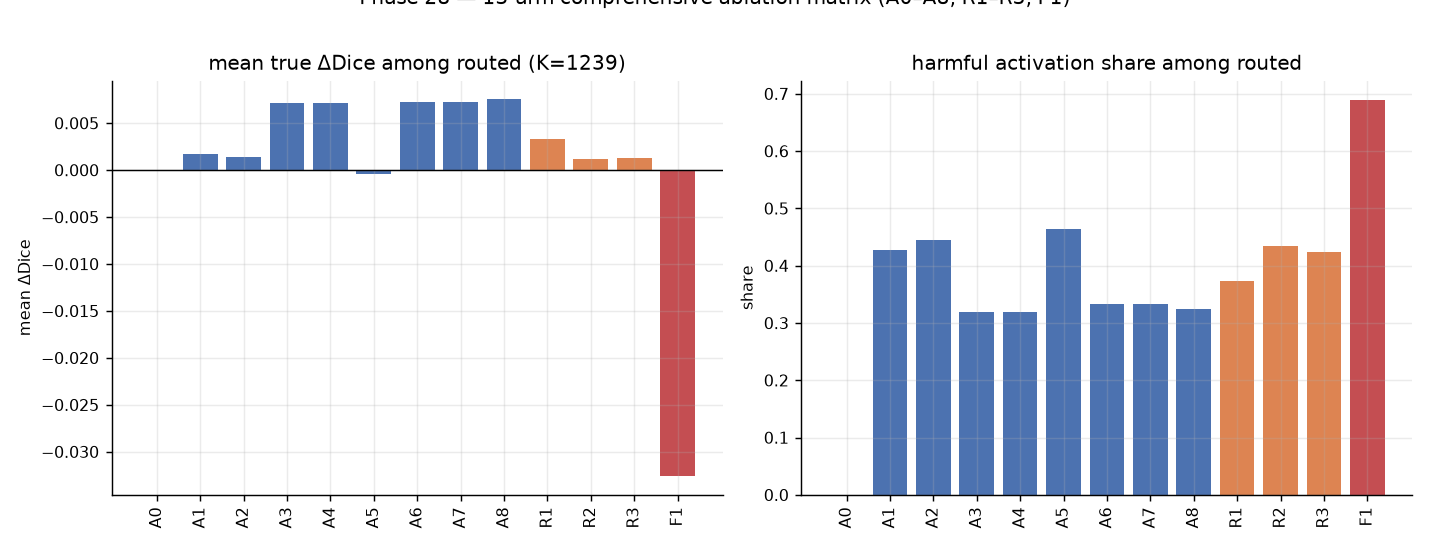

  [2] p28_fig2_router_variant_vs_full.png


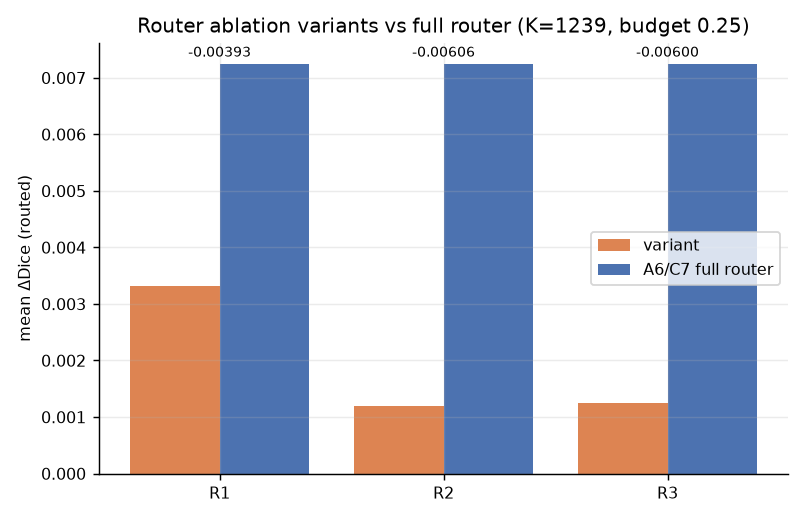

  [3] p28_fig3_router_membership_overlap.png


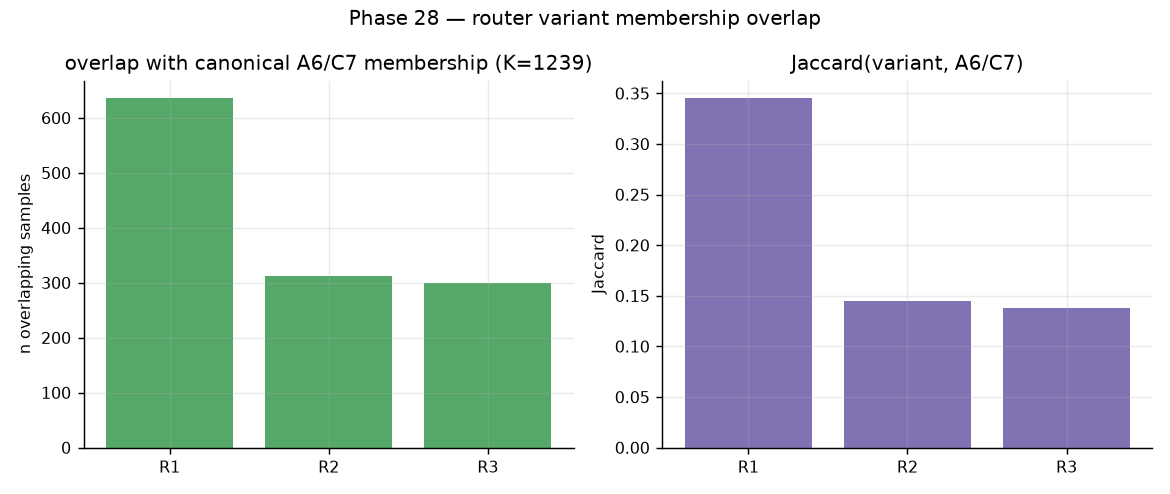

  [4] p28_fig4_bootstrap_ci_forest.png


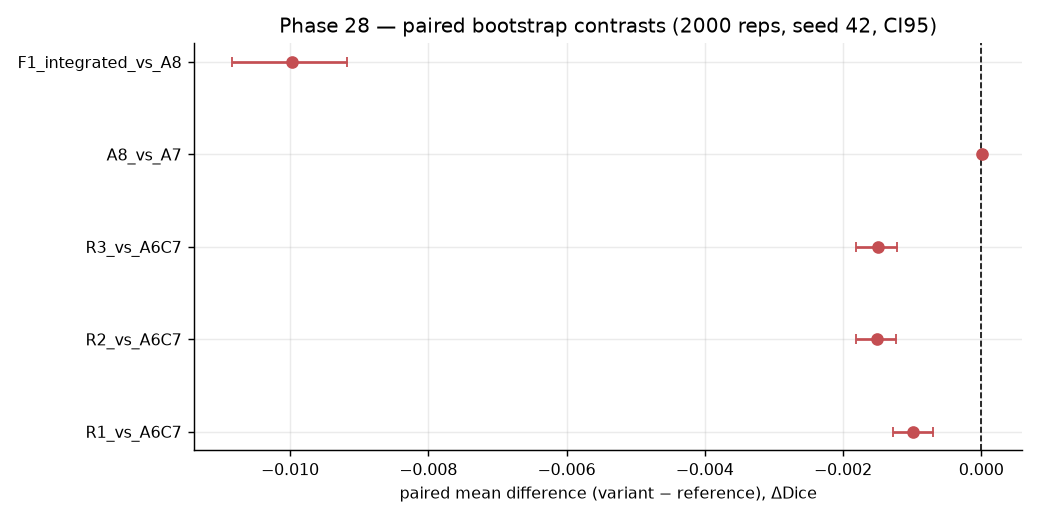

  [5] p28_fig5_f1_refiner_level_delta.png


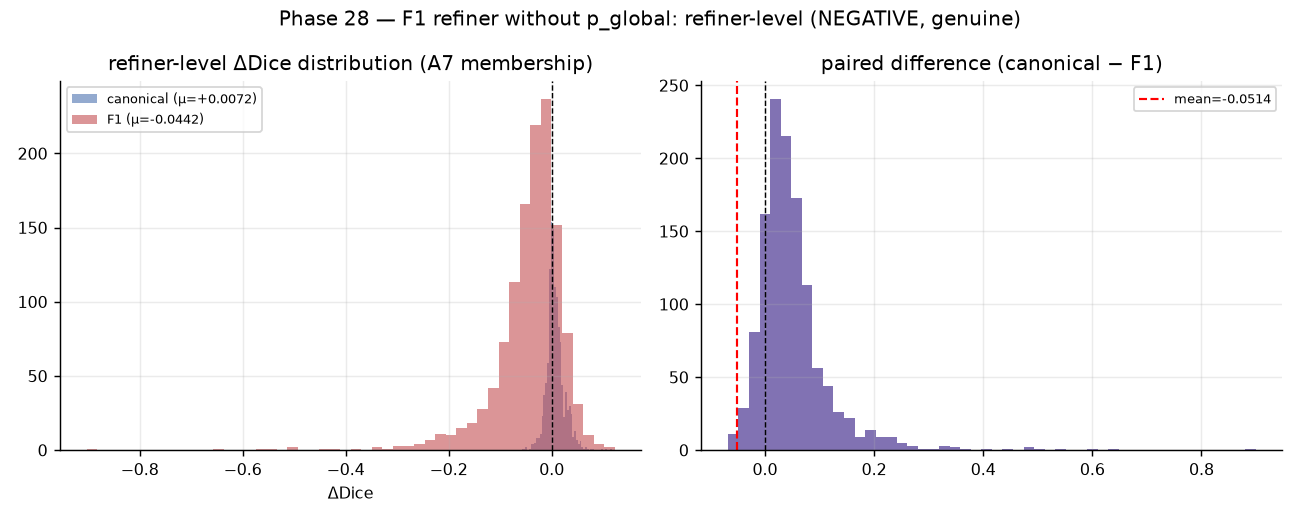

  [6] p28_fig6_f1_integrated_vs_canonical.png


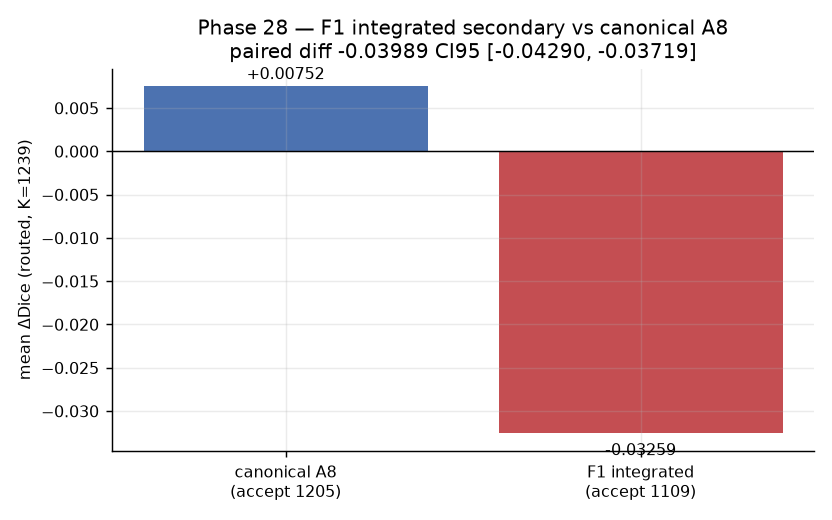

  [7] p28_fig7_fixed_budget_capture.png


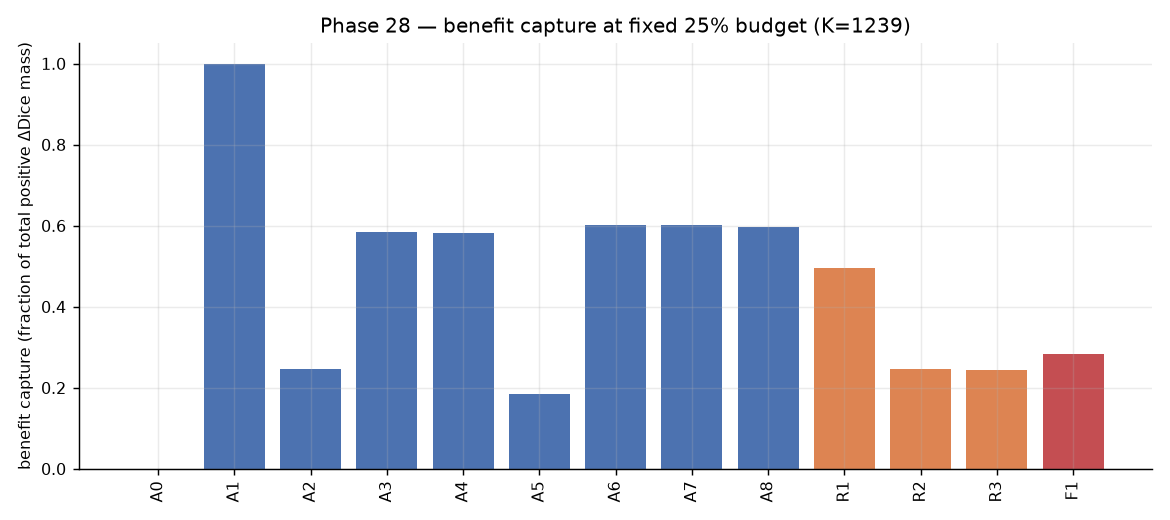

  [8] p28_fig8_training_health.png


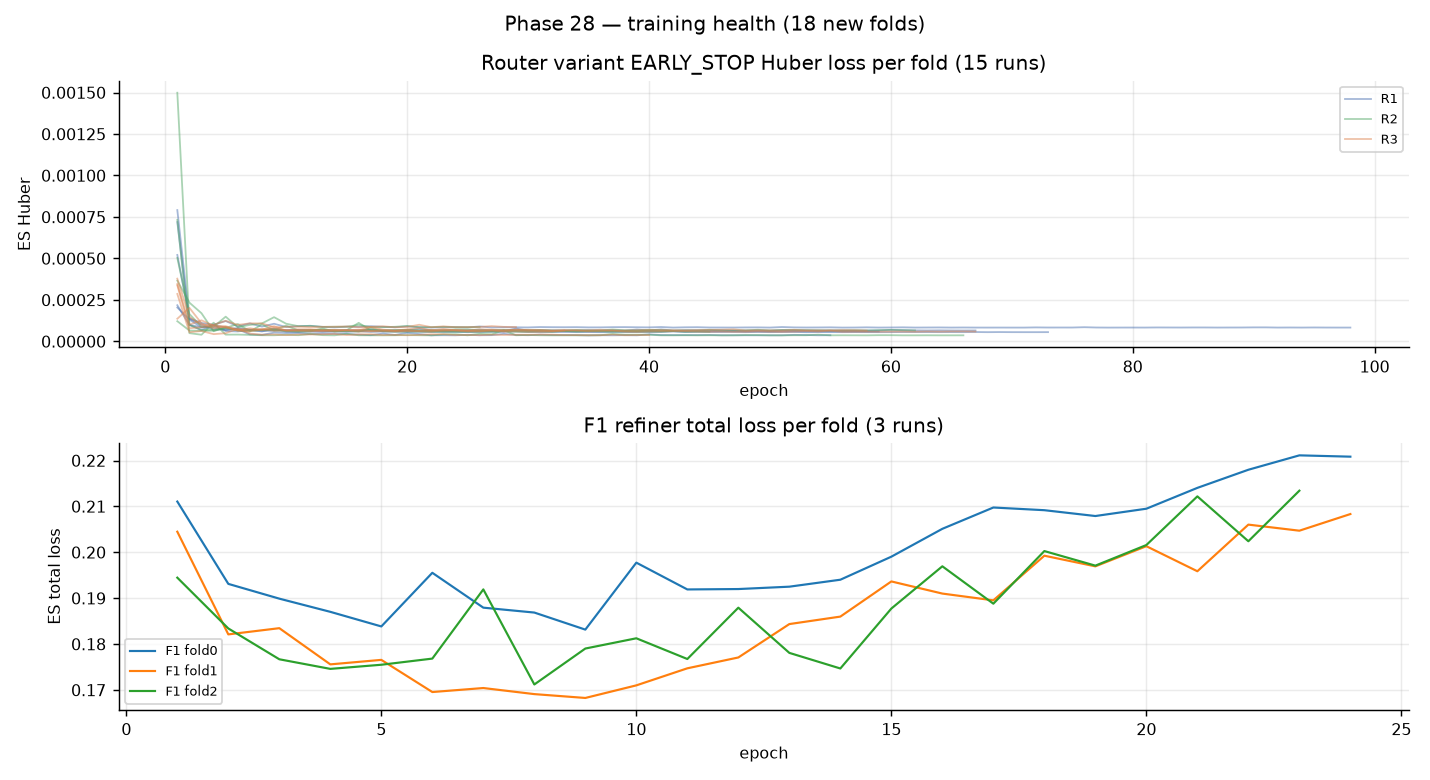

In [41]:
figs = sorted(FIG.glob("p28_fig*.png"))
print(f"frozen figures found: {len(figs)}")
for i, f in enumerate(figs, 1):
    print(f"  [{i}] {f.name}")
    display(Image(filename=str(f)))
assert len(figs) == 8

## 42. Negative-result discipline

Results are reported as measured. The F1 negative result is reported without
suppression. **No deployment winner is selected. The canonical bundle is
unchanged. The deployment model is not replaced.**

In [42]:
nr = J("phase28_negative_result_acceptance.json")
print("negative_result_accepted     :", nr["negative_result_accepted"])
print("reported_without_suppression :", nr["reported_without_suppression"])
print("pipeline_validated_nonartifactual:", nr["pipeline_validated_nonartifactual"])
print("F1 refiner-level mean ΔD     :", nr["f1_refiner_level_mean_delta_dice"])
print("F1 integrated mean ΔD        :", nr["f1_integrated_mean_delta_dice"])
print("interpretation:", nr["interpretation_restraint"])
assert nr["negative_result_accepted"] is True

negative_result_accepted     : True
reported_without_suppression : True
pipeline_validated_nonartifactual: True
F1 refiner-level mean ΔD     : -0.0441799
F1 integrated mean ΔD        : -0.032585339606785245
interpretation: removing p_global from the refiner input degrades refinement; the canonical 4-channel refiner is retained


## 43. Holdout / VAL808 / TEST locks

`ROUTER_HOLDOUT` (n=875) remains locked for Phase 30, `VAL808` (n=808) is not read,
and `TEST` (n=1683) remains locked for Phase 39.

In [43]:
tl = J("phase28_test_lock.json")
hl = J("phase28_phase30_holdout_lock.json")
vl = J("phase28_val808_reuse_rule.json")
print("TEST             :", tl["TEST_state"], "| n =", tl["TEST_n"], "| reads =", tl["phase28_test_reads"])
print("ROUTER_HOLDOUT   :", hl["ROUTER_HOLDOUT_state"], "| n =", hl["ROUTER_HOLDOUT_n"],
      "| reads =", hl["phase28_holdout_reads"])
print("VAL808           : reads =", vl.get("phase28_val808_reads", 0))
assert tl["phase28_test_reads"] == 0 and hl["phase28_holdout_reads"] == 0

TEST             : LOCKED_UNTIL_PHASE39 | n = 1683 | reads = 0
ROUTER_HOLDOUT   : RESERVED_UNOPENED_FOR_PHASE30 | n = 875 | reads = 0
VAL808           : reads = 0


## 44. Final freeze and project status

In [44]:
ff = J("phase28_final_freeze.json")
ps = J("phase28_project_status.json")
print("freeze classification :", ff["classification"])
print("freeze population     :", ff["population"], "n =", ff["population_n"])
print("freeze K              :", ff["K"])
print("freeze arms/tables/figs:", ff["n_arms"], "/", ff["n_tables"], "/", ff["n_figures"])
print("freeze new training runs:", ff["n_new_training_runs"])
print("canonical bundle      :", ff["canonical_bundle_sha256"], "| changed =", ff["canonical_bundle_changed"])
print()
print("project status        :", ps["phase_state"], "|", ps["execution_state"])
print("headline              :", json.dumps(ps["headline_findings"], indent=2)[:600])
assert ff["canonical_bundle_changed"] is False

freeze classification : PHASE28_CANONICAL_COMPREHENSIVE_SYSTEM_ABLATION_EXECUTION
freeze population     : ROUTER_DEVELOPMENT n = 4957
freeze K              : 1239
freeze arms/tables/figs: 13 / 10 / 8
freeze new training runs: 18
canonical bundle      : f7aebb0f646bcc8de49fa91b70a4c4cc1051c9998ab6b055a8d4d187809cb3d9 | changed = False

project status        : COMPLETE | EXECUTED
headline              : {
  "router_ordering": "A6/C7 (full) > R1 > R3 ~ R2",
  "R1_mean_delta": 0.003320469712,
  "R2_mean_delta": 0.001190650496,
  "R3_mean_delta": 0.001250933396,
  "A6_C7_mean_delta": 0.007246629237,
  "f1_refiner_level_mean_delta": -0.0441799,
  "f1_integrated_mean_delta": -0.032585339606785245,
  "A8_mean_delta": 0.007515754298,
  "deployment_winner_selected": false
}


## 45. Terminal state

The frozen Phase-28 terminal:

In [45]:
term = J("phase28_terminal_state.json")
print(term["terminal"])
assert term["terminal"] == (
    "PHASE28_COMPREHENSIVE_ABLATION_MATRIX_COMPLETE__"
    "CORE_ROUTER_AND_REFINER_ABLATIONS_FROZEN__PHASE29_ELIGIBLE_NOT_STARTED")
assert term["exit_class"] == "SUCCESS"
assert term["phase"] == 28
assert term["blocked_terminals"]["PHASE29_STARTED"] is False
assert term["blocked_terminals"]["PHASE30_STARTED"] is False
assert term["blocked_terminals"]["ROUTER_HOLDOUT_OPENED"] is False
assert term["blocked_terminals"]["TEST_OPENED"] is False
print()
print("exit_class       :", term["exit_class"])
print("arms             :", term["n_arms"])
print("new training runs:", term["n_new_training_runs"])
print("tables / figures :", term["n_tables"], "/", term["n_figures"])
print("next phase       :", term["next_phase"], "|", term["next_phase_state"])
print()
print(term["stop_instruction"])
print()
print("REVIEWER NOTEBOOK COMPLIANCE REPAIR: COMPLETE")

PHASE28_COMPREHENSIVE_ABLATION_MATRIX_COMPLETE__CORE_ROUTER_AND_REFINER_ABLATIONS_FROZEN__PHASE29_ELIGIBLE_NOT_STARTED

exit_class       : SUCCESS
arms             : 13
new training runs: 18
tables / figures : 10 / 8
next phase       : PHASE29 | ELIGIBLE_NOT_STARTED

STOP. DO NOT START PHASE29. DO NOT START PHASE30. DO NOT OPEN ROUTER_HOLDOUT. DO NOT OPEN TEST.

REVIEWER NOTEBOOK COMPLIANCE REPAIR: COMPLETE
